# Jet data: sanity audit of the Modane record

`run_jet_SDE.py` trains on `Vit_Modane95.mat` only (since commit 177dedd). This notebook checks that record. All heavy lifting is in `data_audit/audit_modane.py` (same figures via `python data_audit/audit_modane.py` → `data_audit/results/`); the loader is `jet_data.py`. Scales are in **samples** (dt not filled in yet). Runtime ≈ 2 min on CPU.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd() / 'data_audit'))
from jet_data import load_modane_raw, load_modane_windows, describe_modane
import audit_modane as A

WINDOW_LEN, TARGET_LEN, N1 = 1024, 256, 5000   # as in the recent run_jet_SDE runs

v = load_modane_raw()
describe_modane(WINDOW_LEN, N1)

Modane record: N = 25,803,816 samples   {'facility': None, 'rlambda': None, 'dt_s': None, 'units': None}
  U = 20.593   sigma = 1.655   sigma/U = 0.080   min/max = 11.92/30.65
  windows of 1024: 25,199  (n1 = 5,000 -> 20% of the record)
  excluded intervals: none


In [2]:
run_len, run_start = A.zero_increment_runs(v)
rho = A.autocorr(v, max_lag=2 ** 17)
L, _ = A.integral_scale(rho)
F, S = A.increment_stats(v)

## 1. Is the record stationary and glitch-free?
Mean ± std in 100k-sample blocks, plus places where the signal is frozen (stuck probe).

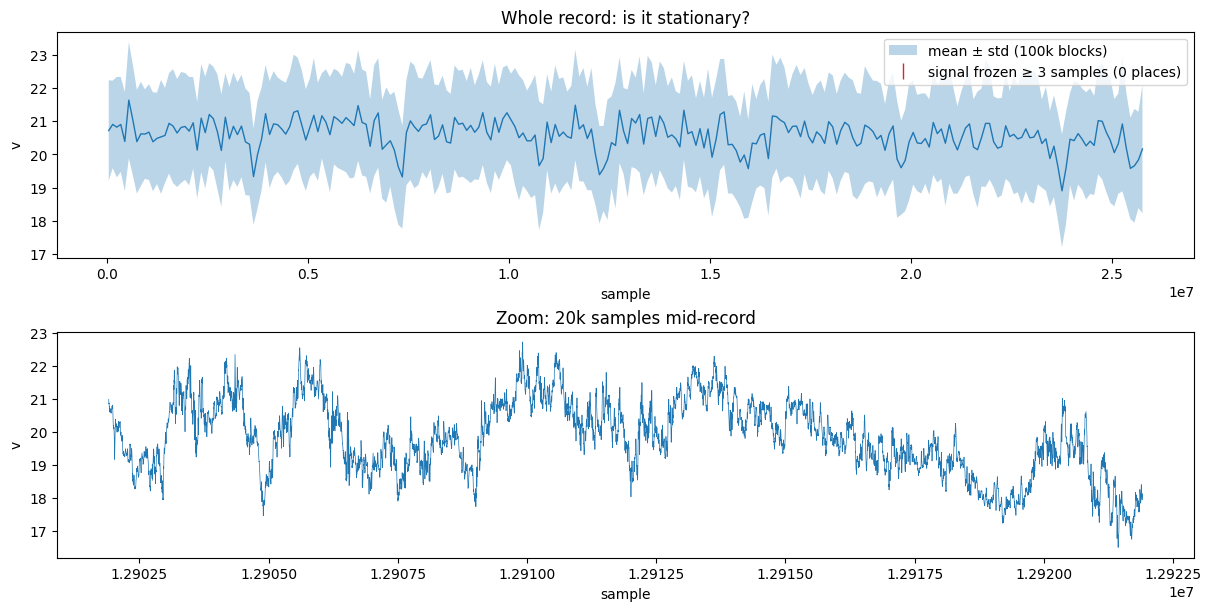

In [3]:
A.fig_overview(v, run_len, run_start);

**Verdict:** stationary. Block means wander by 0.26σ, close to the ≈ 0.21σ that large eddies alone produce (σ·√(2L/100k), see section 4); the small excess is the slow drift seen in section 4. No frozen stretch (longest run of equal samples: 2). No NaN/inf.

## 2. One-point velocity PDF

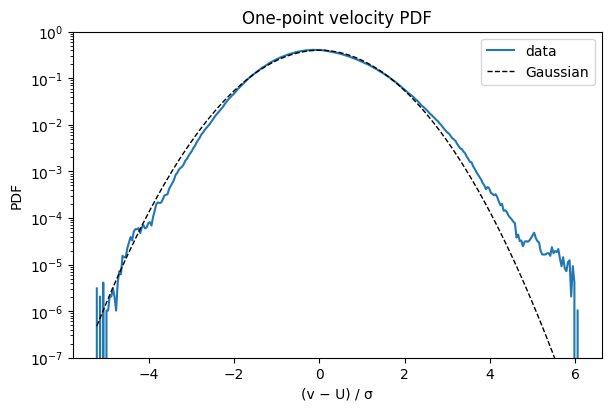

In [4]:
A.fig_pdf(v);

**Verdict:** U = 20.59, σ = 1.66 (σ/U = 8%, so Taylor's hypothesis is reasonable). Nearly Gaussian (skewness 0.17, flatness 3.10). No pile-up at min/max (each reached once): no clipping. Resolution is float32 (value grid 2⁻²⁰).

## 3. Energy spectrum
The three thirds of the record are overlaid: any instrument drift would separate them.

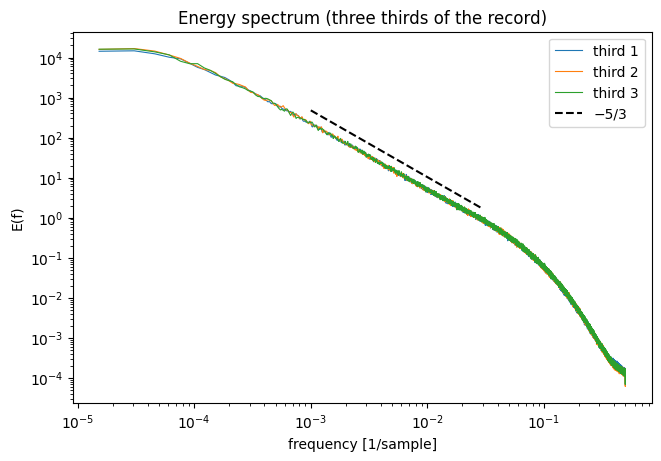

In [5]:
A.fig_spectrum(v);

**Verdict:** the three thirds coincide. A clean −5/3 range over ~1.5 decades, then a dissipation range; no spurious peaks, no visible noise floor except a slight flattening at the very last bins.

## 4. Correlation length → how many independent windows?

L = 2131 samples;  rho(window) = 0.52;  independent stretches of 2L in the record: 6053


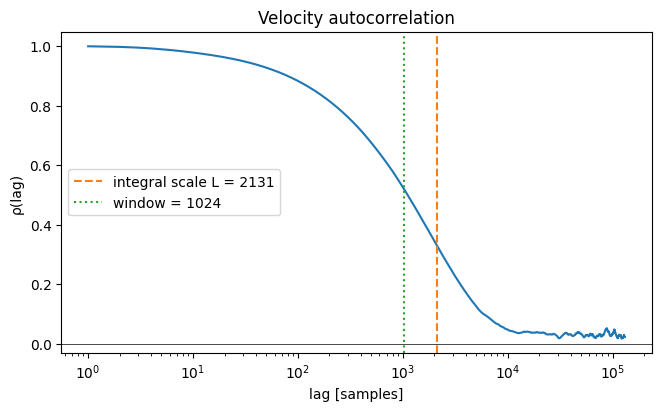

In [6]:
A.fig_autocorr(rho, L, WINDOW_LEN);
print(f'L = {L:.0f} samples;  rho(window) = {rho[WINDOW_LEN]:.2f};  '
      f'independent stretches of 2L in the record: {v.size / (2 * L):.0f}')

**Verdict:** integral scale L ≈ 2100 samples. A 1024 window is ~½ L, so adjacent windows are strongly correlated (ρ ≈ 0.5). The whole record has ≈ 6000 independent stretches; `n1 = 5000` consecutive windows (the first 20% of the record) would carry only ≈ 1200 of them, hence `run_jet_SDE.py` now draws the n1 windows at random over the whole record (`--n1_spread`, default). ρ never reaches 0 but levels off at ≈ 0.02 (very slow drift of the mean flow), so L is integrated until ρ < 0.05.

## 5. Increments: is it turbulence (intermittency)?

skewness of increments vs lag: {1: np.float64(0.49), 2: np.float64(0.44), 4: np.float64(0.36), 8: np.float64(0.29), 16: np.float64(0.27), 32: np.float64(0.26)}


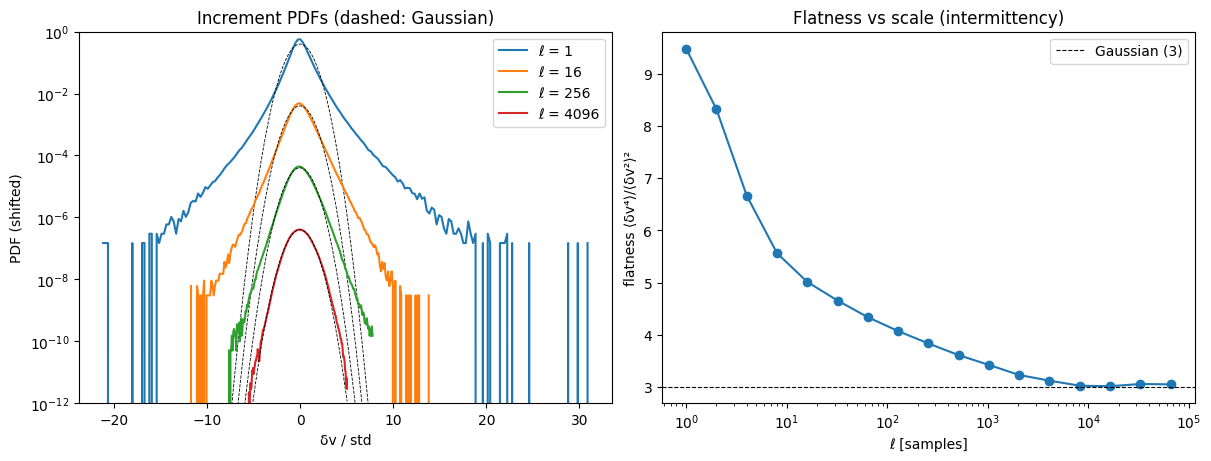

In [7]:
A.fig_increments(v, F);
print('skewness of increments vs lag:', dict(zip(A.LAGS[:6].tolist(), np.round(S[:6], 2))))

**Verdict:** textbook. PDFs go from Gaussian at large scales to fat-tailed at small ones; flatness rises from 3 (ℓ ≳ 8000) to 9.5 (ℓ = 1). Increment skewness is **positive** (+0.49 at ℓ = 1): expected for a time signal, since Taylor's x = −Ut flips the sign of the usual negative spatial skewness. The ±20–30σ points at ℓ = 1 (72 in the record) are sharp fronts that persist, not one-sample spikes.

## 6. What the model actually sees
Windows built exactly as in `run_jet_SDE.py`: periodized windows → Db3 decimation → n1 windows drawn at random over the record (fixed seed; `--n1_spread`, default) → standardized. Plot: the random selection; printout: how well the training set matches the rest of the record, random vs first-n1.

first  n1: rest of record in train units: mean -0.087, std 1.040


random n1: rest of record in train units: mean +0.017, std 0.989


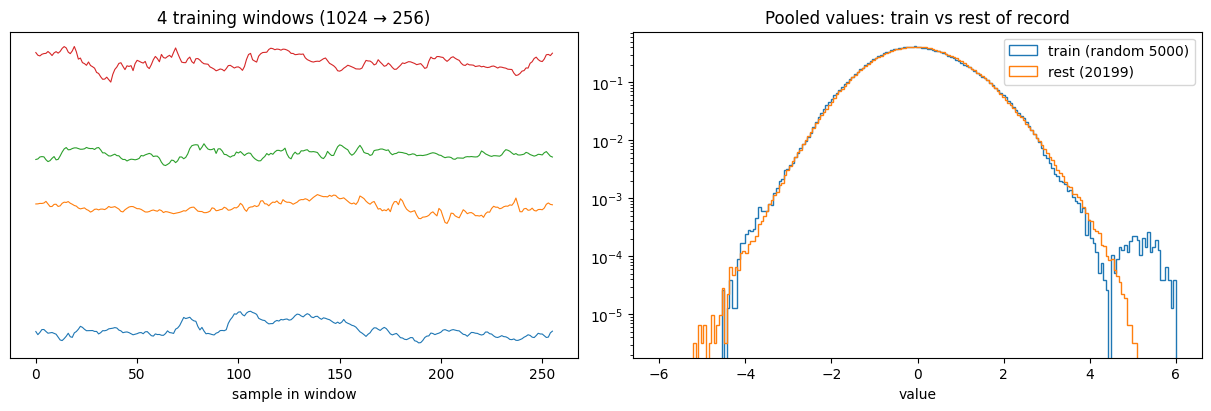

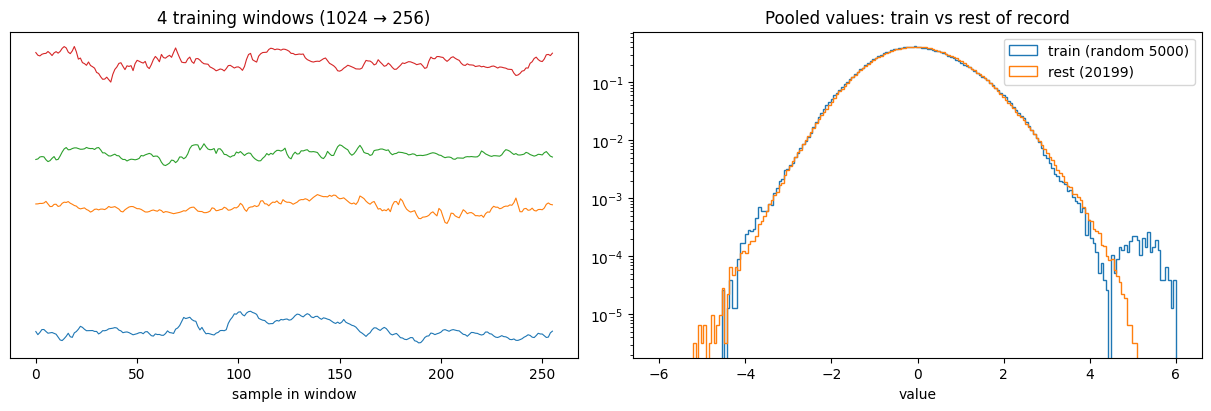

In [8]:
for spread in (False, True):
    fig, (n_win, rest_mean, rest_std) = A.fig_model_windows(WINDOW_LEN, TARGET_LEN, N1, spread=spread)
    print(f"{'random' if spread else 'first '} n1: rest of record in train units: mean {rest_mean:+.3f}, std {rest_std:.3f}")
    if not spread:
        plt.close(fig)
fig

**Verdict:** taking the first 5000 windows gives a slightly biased training set (rest of the record offset by −0.09σ and 4% wider: the first 20% is a bit faster and calmer). Drawing them at random over the whole record removes this (+0.02σ, 1%) and spreads the training set over all ≈ 6000 independent stretches of the record instead of ≈ 1200. About 19% of the random picks still sit next to another pick.

## Summary

| check | result |
|---|---|
| missing / NaN | none |
| clipping | none |
| stuck probe | none (longest frozen run 2 samples) |
| stationarity | yes (spectra of thirds coincide) |
| turbulence signatures | −5/3 range, flatness 3 → 9.5, skewness +0.49 |
| integral scale | ≈ 2100 samples |
| windows of 1024 | 25199 total, ≈ 6000 independent |
| training windows | n1 random over the record (fixed seed), not consecutive |
| excluded intervals | none, the whole record is usable |
